# 02 · A word2vec map of the tweets: where do FinBERT's Neutral errors live?
**AI & Vis UE · Phase I · AI-aided pair: Dharmik & Sarang** · input: `results_train.csv` (from `00_baseline_finbert.ipynb`)

Suggested at the feedback session (06.11): use a word embedding to see how tweets are organised and where errors cluster.
- **word2vec is trained here on the tweets themselves** (train split). It is a small, separate model, not FinBERT, so we still never look inside FinBERT (Phase I = black box).
- Each tweet becomes the IDF-weighted average of its word vectors, then UMAP projects all tweets to 2D.
- Clusters are found in the full 100-dimensional space (k-means), not in the 2D picture, so the map's distortions do not decide the groups.

In [1]:
!pip -q install gensim umap-learn

In [2]:
import re, numpy as np, pandas as pd, matplotlib.pyplot as plt
from gensim.models import Word2Vec
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
import umap, os
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 110)
BLUE, ORANGE, GRAY, INK, LIGHT = "#2a78d6", "#eb6834", "#8c8b85", "#52514e", "#dcdbd4"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c8c7c0",
                     "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "axes.titleweight": "bold",
                     "axes.titlesize": 11, "font.size": 9.5, "figure.dpi": 110})
os.makedirs("figures", exist_ok=True)
SEED = 42

d = pd.read_csv("results_train.csv"); d["err"] = ~d.correct
def wilson(k, n, z=1.96):
    p = k / n; den = 1 + z**2 / n
    c = (p + z**2 / (2*n)) / den; h = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / den
    return c - h, c + h

# Tokens: tickers, percentages and numbers become placeholder words, so "$AAPL +4%" and "$TSLA +9%" look alike
def tokenize(s):
    s = s.lower()
    s = re.sub(r"https?://\S+", " ", s)
    s = re.sub(r"\$[a-z]+", " tickersym ", s)
    s = re.sub(r"[+-]?\d+(?:\.\d+)?%", " pctnum ", s)
    s = re.sub(r"\d+(?:[.,]\d+)*", " num ", s)
    return re.findall(r"[a-z][a-z']+", s)
toks = d.text.map(tokenize)
print(f"{len(d)} tweets, {toks.map(len).mean():.1f} tokens per tweet on average")

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


9543 tweets, 11.4 tokens per tweet on average


## 1 · Train word2vec and check that it learned something sensible

In [3]:
w2v = Word2Vec(toks.tolist(), vector_size=100, window=5, min_count=3, sg=1, epochs=40, workers=1, seed=SEED)
print("vocabulary:", len(w2v.wv), "words")
probe = ["china", "beats", "misses", "downgrade", "dividend", "virus", "fed", "oil"]
pd.DataFrame({w: [x for x, _ in w2v.wv.most_similar(w, topn=6)] for w in probe}).T.rename(columns=lambda i: f"#{i+1}")

vocabulary: 4639 words


,#1,#2,#3,#4,#5,#6
china,tariffs,ip,beijing,dominates,linger,doubts
beats,revs,eps,cigna,levi,strauss,nii
misses,ffo,cigna,nii,levi,eps,strauss
downgrade,reflects,baml,inventories,sticks,notch,kellogg
dividend,declares,quarterly,cad,shs,bankfinancial,superior
virus,coronavirus,outbreak,fears,ore,chaos,uncertain
fed,powell,fed's,fomc,qe,shelton,bernanke
oil,crude,opec,producers,output,opec's,shale


**What it shows:** for a few probe words, their nearest neighbours in the word2vec space trained on our tweets.
**What we see:** the neighbours make sense: *beats ↔ revs, eps*; *virus ↔ coronavirus, outbreak*; *fed ↔ powell, fomc*; *oil ↔ crude, opec*; *dividend ↔ declares, quarterly*.
**What it means:** although trained on only ~9.5k tweets, the embedding captures topics well enough to organise the tweets on a map.

In [4]:
# Tweet vectors: IDF-weighted mean of word vectors (rare, informative words count more than "the", "stock" ...)
tf = TfidfVectorizer(analyzer=lambda x: x).fit(toks)
idf = dict(zip(tf.get_feature_names_out(), tf.idf_))
def tweet_vec(t):
    ws = [w for w in t if w in w2v.wv]
    return np.average([w2v.wv[w] for w in ws], axis=0, weights=[idf[w] for w in ws]) if ws else np.zeros(100)
V = np.vstack(toks.map(tweet_vec))
V = V / np.maximum(np.linalg.norm(V, axis=1, keepdims=True), 1e-9)
# n_neighbors=100 keeps the global layout; with small values a few template islands stretch the map
xy = umap.UMAP(n_neighbors=100, min_dist=.5, metric="cosine", random_state=SEED).fit_transform(V)
d["x"], d["y"] = xy[:, 0], xy[:, 1]

/usr/local/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


## 2 · Clusters in word2vec space

In [5]:
K = 14
d["cl"] = KMeans(n_clusters=K, n_init=10, random_state=0).fit_predict(V)
STOP = set("the a an of to in on for and is at by with from as it its be are this that will vs after new us up num tickersym".split())
base = pd.Series([w for t in toks for w in set(t)]).value_counts()
def top_words(idx, k=4):
    w = pd.Series([x for t in toks[idx] for x in set(t)]).value_counts()
    lift = (w / len(idx)) / (base[w.index] / len(d))
    keep = (w >= max(5, len(idx) * .06)) & ~lift.index.isin(STOP)
    return list(lift[keep].sort_values(ascending=False).index[:k])
rows = []
for c, s in d.groupby("cl"):
    N = s[s.true == "Neutral"]
    rows.append(dict(cl=c, n=len(s), topic=", ".join(top_words(s.index)), err=s.err.mean(), neutral=len(N) / len(s),
                     n_neutral=len(N), neutral_err=N.err.mean(), cx=s.x.median(), cy=s.y.median()))
P = pd.DataFrame(rows).sort_values("neutral_err", ascending=False)
P.drop(columns=["cx", "cy"]).round(2)

,cl,n,topic,err,neutral,n_neutral,neutral_err
0,0,399,"factset, misses, beats, eps",0.31,0.21,83,0.59
3,3,1112,"coronavirus, fed, economy, china",0.41,0.57,638,0.51
10,10,1236,"dow, market, update, trade",0.27,0.28,346,0.42
1,1,1017,"trump, says",0.41,0.88,900,0.42
11,11,895,"billion, million, deal, pctnum",0.35,0.79,705,0.34
12,12,284,"raised, overweight, upgraded, suntrust",0.25,0.11,32,0.25
13,13,770,"premarket, offering, among, shares",0.31,0.49,375,0.25
5,5,1572,"you, how, what, have",0.24,0.80,1253,0.19
9,9,630,"hedge, funds, nyse, inc",0.29,0.71,446,0.16
8,8,425,"marketscreener, announces, stock",0.16,0.92,392,0.13


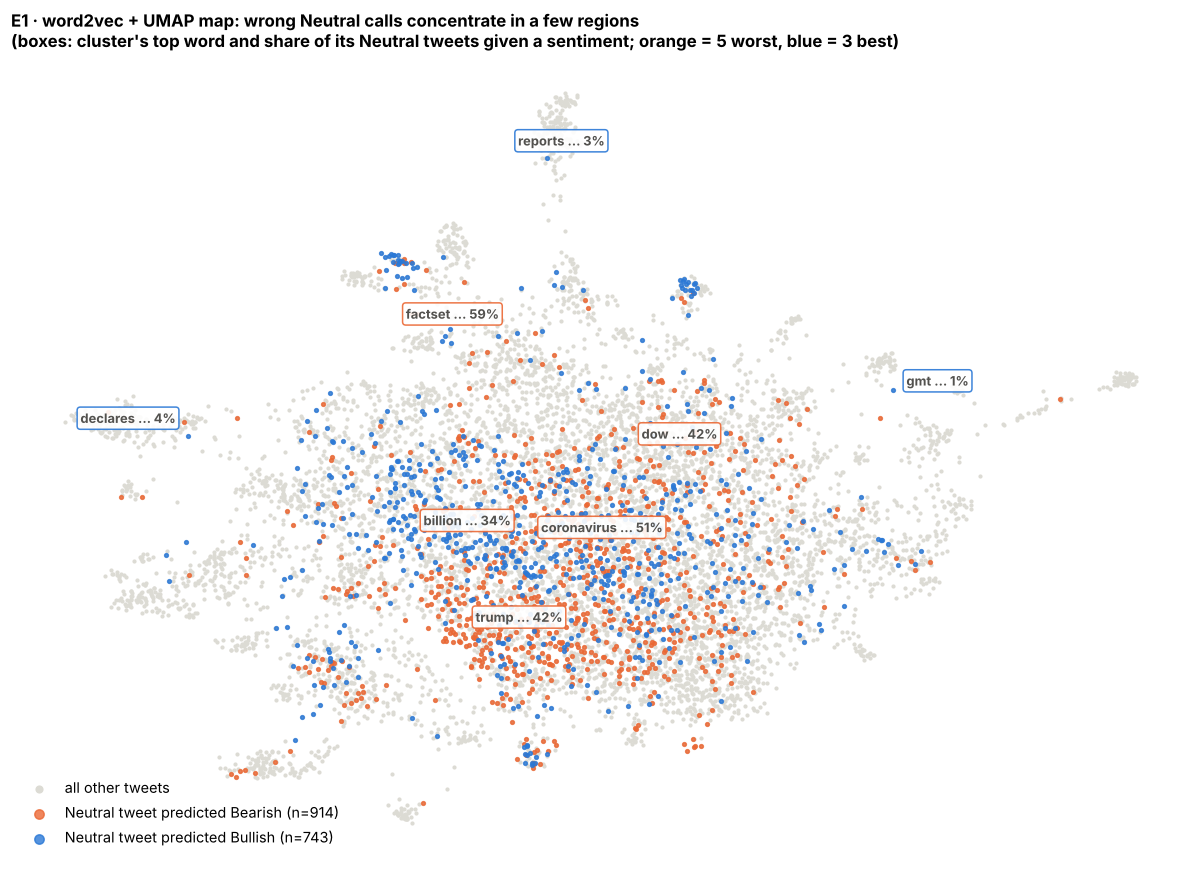

In [6]:
# Map: all tweets in light grey; Neutral tweets FinBERT got wrong in colour (our direction)
fig, ax = plt.subplots(figsize=(11, 8))
ax.scatter(d.x, d.y, s=3, c=LIGHT, label="all other tweets", rasterized=True)
for pred, col in [("Bearish", ORANGE), ("Bullish", BLUE)]:
    m = (d.true == "Neutral") & (d.pred == pred)
    ax.scatter(d.x[m], d.y[m], s=6, c=col, alpha=.8, label=f"Neutral tweet predicted {pred} (n={m.sum()})", rasterized=True)
top = P.head(5).cl.tolist(); low = P.tail(3).cl.tolist()
for r in P.itertuples():
    if r.cl in top + low:
        ax.annotate(f"{r.topic.split(', ')[0]} … {r.neutral_err:.0%}", (r.cx, r.cy), ha="center", fontsize=8.5, weight="bold",
                    color=INK, bbox=dict(boxstyle="round,pad=.25", fc="white", ec=ORANGE if r.cl in top else BLUE, alpha=.9))
ax.set_xticks([]); ax.set_yticks([]); ax.spines[["left", "bottom"]].set_visible(False)
ax.legend(frameon=False, loc="lower left", markerscale=2.5)
ax.set_title("E1 · word2vec + UMAP map: wrong Neutral calls concentrate in a few regions\n"
             "(boxes: cluster's top word and share of its Neutral tweets given a sentiment; orange = 5 worst, blue = 3 best)", loc="left")
plt.tight_layout(); plt.savefig("figures/E1_w2v_map.png", dpi=160); plt.show()

**What it shows:** every tweet as a dot, placed by word2vec similarity (similar wording → close together). Coloured: Neutral tweets FinBERT called Bearish (orange) or Bullish (blue). Boxes: the 5 worst and 3 best clusters, with the share of their Neutral tweets given a sentiment.
**What we see:** wrong calls are not spread evenly. Orange concentrates in the lower centre (politics, *trump*, *coronavirus*, economy); blue appears more around *billion/deal* and in small earnings islands. Template regions (*declares* dividends, *reports* results, *edited* transcripts) are almost free of errors.
**What it means:** the Neutral errors live in specific kinds of news, which the next two figures quantify.

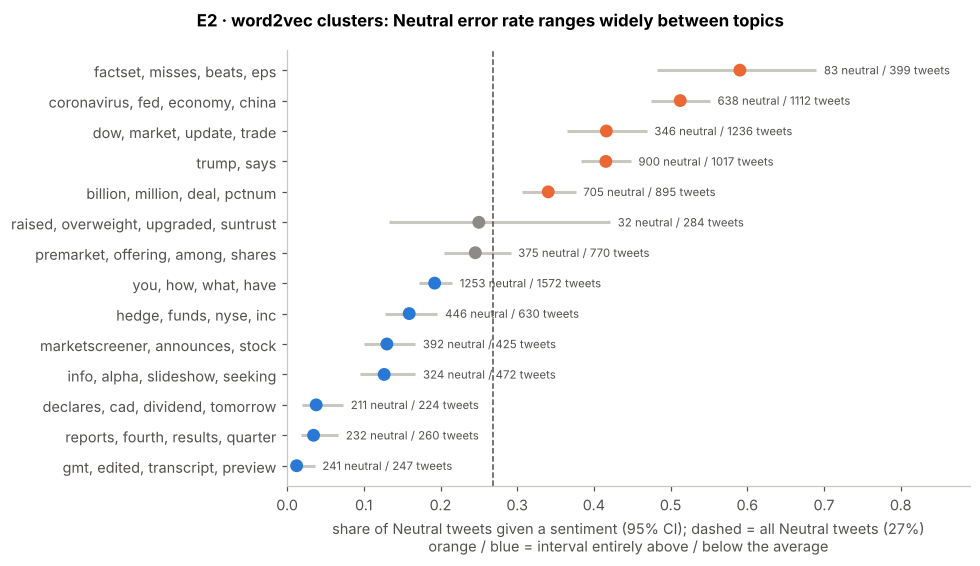

In [7]:
# E2 · Error rate of Neutral tweets per cluster, with 95% intervals
Q = P.sort_values("neutral_err")
lo, hi = map(np.array, zip(*[wilson(r.neutral_err * r.n_neutral, r.n_neutral) for r in Q.itertuples()]))
avg = d[d.true == "Neutral"].err.mean()
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.errorbar(Q.neutral_err, Q.topic, xerr=[Q.neutral_err - lo, hi - Q.neutral_err], fmt="none", ecolor="#c8c7c0", lw=2)
ax.scatter(Q.neutral_err, Q.topic, s=55, zorder=3, c=[ORANGE if l > avg else BLUE if h < avg else GRAY for l, h in zip(lo, hi)])
ax.axvline(avg, ls="--", c=INK, lw=1)
for r, h in zip(Q.itertuples(), hi): ax.text(h + .01, r.topic, f"{r.n_neutral} neutral / {r.n} tweets", va="center", fontsize=7.5, color=INK)
ax.set_xlim(0, max(hi) + .2); ax.set_xlabel(f"share of Neutral tweets given a sentiment (95% CI); dashed = all Neutral tweets ({avg:.0%})\n"
                                            "orange / blue = interval entirely above / below the average")
fig.suptitle("E2 · word2vec clusters: Neutral error rate ranges widely between topics", weight="bold", fontsize=11)
plt.tight_layout(); plt.savefig("figures/E2_w2v_cluster_errors.png", dpi=160); plt.show()

**What it shows:** the 14 word2vec clusters (found in the full 100-d space), with the share of their Neutral tweets that FinBERT gave a sentiment, and 95% intervals.
**What we see:** earnings headlines (*misses, beats, eps*) 59%, coronavirus/Fed/economy/China 51%, market updates and *trump* 42%, deals/amounts 34%; dividends 4%, quarterly results 3%, transcripts 1%. Average: 27%.
**What it means:** an independent grouping method (word2vec instead of TF-IDF in B4) gives the same picture: news with a clear tone but no clear stock stance fails, fixed announcement templates do not. Two methods agreeing makes the finding more robust.

## 3 · Inside the worst cluster: do sub-clusters behave differently?
The assignment asks to go beyond "this cluster has many errors". We split the worst cluster again and compare.

worst cluster: factset, misses, beats, eps  (n=399, Neutral error 59%)


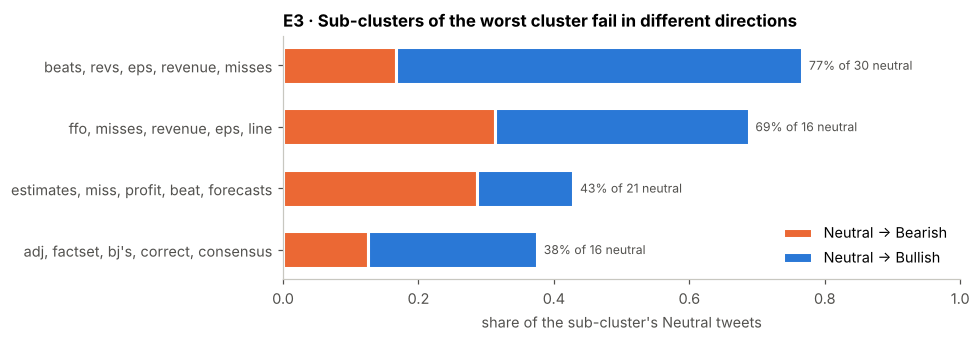

,sub,n,topic,neutral,n_neutral,neutral_err,to_bearish,to_bullish
1,1,113,"beats, revs, eps, revenue, misses",0.27,30,0.77,0.17,0.60
2,2,70,"ffo, misses, revenue, eps, line",0.23,16,0.69,0.31,0.38
0,0,138,"estimates, miss, profit, beat, forecasts",0.15,21,0.43,0.29,0.14
3,3,78,"adj, factset, bj's, correct, consensus",0.21,16,0.38,0.12,0.25


In [8]:
worst = P.iloc[0].cl
W = d[d.cl == worst].copy()
W["sub"] = KMeans(n_clusters=4, n_init=10, random_state=0).fit_predict(V[W.index])
S = []
for c, s in W.groupby("sub"):
    N = s[s.true == "Neutral"]
    S.append(dict(sub=c, n=len(s), topic=", ".join(top_words(s.index, 5)), neutral=len(N) / len(s), n_neutral=len(N),
                  neutral_err=N.err.mean(), to_bearish=(N.pred == "Bearish").mean(), to_bullish=(N.pred == "Bullish").mean()))
S = pd.DataFrame(S).sort_values("neutral_err", ascending=False)
print(f"worst cluster: {P.iloc[0].topic}  (n={P.iloc[0].n}, Neutral error {P.iloc[0].neutral_err:.0%})")

fig, ax = plt.subplots(figsize=(9, 3.2)); y = np.arange(len(S))
ax.barh(y, S.to_bearish, color=ORANGE, height=.6, edgecolor="white", linewidth=2, label="Neutral → Bearish")
ax.barh(y, S.to_bullish, left=S.to_bearish, color=BLUE, height=.6, edgecolor="white", linewidth=2, label="Neutral → Bullish")
for i, r in enumerate(S.itertuples()):
    ax.text(r.neutral_err + .01, i, f"{r.neutral_err:.0%} of {r.n_neutral} neutral", va="center", fontsize=8, color=INK)
ax.set_yticks(y, S.topic); ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel("share of the sub-cluster's Neutral tweets")
ax.legend(frameon=False, loc="lower right")
ax.set_title("E3 · Sub-clusters of the worst cluster fail in different directions", loc="left")
plt.tight_layout(); plt.savefig("figures/E3_worst_cluster_subclusters.png", dpi=160); plt.show()
S.round(2)

**What it shows:** the worst cluster (earnings headlines) split into 4 sub-clusters; bars = share of Neutral tweets called Bearish (orange) or Bullish (blue).
**What we see:** the "EPS beats by $X, misses on revenue" template fails most (77%) and mostly towards Bullish; the "estimates / forecasts" sub-cluster fails less (43%) and leans Bearish. Note the small numbers (16–30 Neutral tweets per sub-cluster).
**What it means:** inside one topic, the *template* matters: when *beats* and *misses* appear together, FinBERT picks a side (usually Bullish), matching B6. Sub-cluster sizes are small, so this is a lead for Phase II, not a final result.

In [9]:
# Examples from the sub-clusters (read them: this is where the "why" comes from)
for r in S.itertuples():
    s = W[(W["sub"] == r.sub) & (W.true == "Neutral") & W.err]
    print(f"\n=== sub-cluster {r.sub}: {r.topic}")
    print(s.sample(min(5, len(s)), random_state=1)[["text", "pred", "confidence"]].assign(text=lambda x: x.text.str[:100]).to_string(index=False))


=== sub-cluster 1: beats, revs, eps, revenue, misses
                                                                              text    pred  confidence
                             TransDigm Group EPS beats by $0.34, misses on revenue Bullish    0.661488
                                      Qudian EPS misses by $0.04, beats on revenue Bearish    0.599442
$ELY - Callaway Golf EPS misses by $0.03, beats on revenue https://t.co/WWcCPLqZK5 Bearish    0.381337
                                      Kohl's EPS misses by $0.12, beats on revenue Bullish    0.573419
                                  Total S.A. EPS beats by $0.16, misses on revenue Bullish    0.798013

=== sub-cluster 2: ffo, misses, revenue, eps, line
                                                                                           text    pred  confidence
$DVA - DaVita HealthCare Partners EPS beats by $0.26, misses on revenue https://t.co/TipgMhhGpE Bullish    0.724346
         $FRT - Federal Realty Q4 FFO misses

## Notes
- word2vec is trained on only ~9.5k short tweets, so the vectors are rough; the nearest-neighbour check (section 1) shows they still capture topics.
- k = 14 and the UMAP settings are our choices. The map is for orientation; the cluster statistics (E2, E3) are computed in the 100-d space.
- Pre-trained vectors (e.g. GloVe via `gensim.downloader`) would be an alternative; we kept a self-trained model so it reflects the vocabulary of financial tweets (tickers, "eps", "revs", ...).